# XGBoost Explainability — SHAP, LIME, Counterfactuals

Explaining the XGBoost model's decision for one case-study client. Setup: 30,000 clients, 23 features, 80/20 split (seed 42), decline if P(default) ≥ 0.50, case-study **client 24155**. SHAP uses 100 background clients, LIME 5,000 samples × 20 seeds, reasons compared as the **top 4**, DiCE constrained to September's status, bill and payment.

`pip install xgboost shap lime dice-ml xlrd`

## 0. Data, model and client (same as `03_xgboost.ipynb`)

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import shap, dice_ml
from lime.lime_tabular import LimeTabularExplainer
from scipy.special import logit
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

RANDOM_STATE, THRESHOLD, TOP_K = 42, 0.50, 4
pd.set_option("display.max_columns", None)

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df = pd.read_excel("../data/default of credit card clients.xls", header=1)
df = df.rename(columns={"default payment next month": "DEFAULT"})
X, y = df.drop(columns=["ID", "DEFAULT"]), df["DEFAULT"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

categorical_features = ["SEX", "EDUCATION", "MARRIAGE"]
numeric_features = [c for c in X.columns if c not in categorical_features]
preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_features),
    ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
], verbose_feature_names_out=False)
X_train_p = preprocessor.fit_transform(X_train)
X_test_p = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

# Same hyperparameters and early stopping as 03_xgboost.ipynb
def make_xgb(seed=RANDOM_STATE):
    return XGBClassifier(max_depth=4, min_child_weight=5, n_estimators=2000, learning_rate=0.03,
                         subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0, eval_metric="logloss",
                         early_stopping_rounds=50, tree_method="hist", random_state=seed, n_jobs=-1)

X_tr, X_val, y_tr, y_val = train_test_split(X_train_p, y_train, test_size=0.15, stratify=y_train, random_state=RANDOM_STATE)
xgb_model = make_xgb()
xgb_model.fit(X_tr, y_tr, eval_set=[(X_tr, y_tr), (X_val, y_val)], verbose=False)
y_proba = xgb_model.predict_proba(X_test_p)[:, 1]
print("Test ROC-AUC:", round(roc_auc_score(y_test, y_proba), 4), "(03 recorded 0.7805)")

Test ROC-AUC: 0.7805 (03 recorded 0.7805)


In [3]:
# Raw features in -> probabilities out (used by LIME and DiCE)
def xgb_predict_proba_raw(X_input):
    if not isinstance(X_input, pd.DataFrame):
        X_input = pd.DataFrame(X_input, columns=X_train.columns)
    return xgb_model.predict_proba(preprocessor.transform(X_input))

CLIENT_ID = 24155
APPLICANT = df.index[df["ID"] == CLIENT_ID][0]   # row 24154, in the test set
x_applicant = X_test.loc[[APPLICANT]]
x0 = x_applicant.iloc[0]
p_applicant = xgb_predict_proba_raw(x_applicant)[0, 1]
print(f"Client {CLIENT_ID}: P(default) = {p_applicant:.3f} -> declined | actually defaulted: {y_test[APPLICANT]}")
x_applicant

Client 24155: P(default) = 0.700 -> declined | actually defaulted: 1


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
24154,110000,1,2,2,29,2,2,2,2,0,0,55700,58362,56598,51908,48647,47862,5000,2500,0,2000,2000,1854


## 1. SHAP

Splits the prediction (in log-odds) into one contribution per feature: **base value + sum of SHAP values = model output**. TreeSHAP is exact for XGBoost. One-hot columns are summed back into `SEX`, `EDUCATION` and `MARRIAGE`, so each of the 23 original features gets one value.

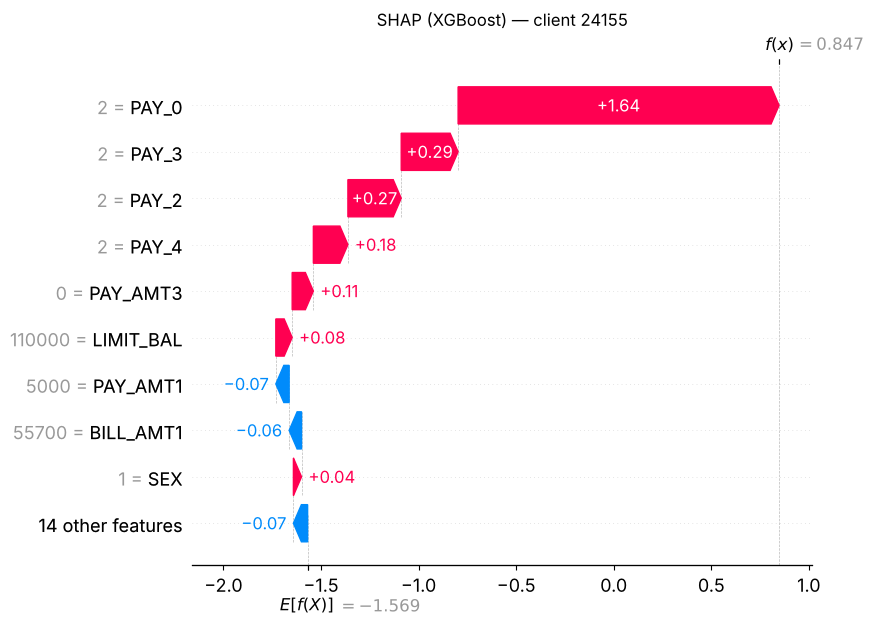

In [4]:
background = preprocessor.transform(shap.sample(X_train, 100, random_state=RANDOM_STATE))
explainer = shap.TreeExplainer(xgb_model, data=background, feature_perturbation="interventional", model_output="raw")
base_value = float(np.ravel(explainer.expected_value)[0])

# 33 model columns -> 23 original features (e.g. SEX_1 + SEX_2 -> SEX)
original = [n if n in numeric_features else n.rsplit("_", 1)[0] for n in feature_names]
to_raw = pd.get_dummies(pd.Series(original)).reindex(columns=X_train.columns, fill_value=0).astype(float).values

def shap_raw(X_raw, expl=explainer):
    return pd.DataFrame(expl.shap_values(preprocessor.transform(X_raw)) @ to_raw, index=X_raw.index, columns=X_train.columns)

shap_applicant = shap_raw(x_applicant).iloc[0]
assert np.isclose(base_value + shap_applicant.sum(), logit(p_applicant), atol=1e-3)   # additivity check

shap.plots.waterfall(shap.Explanation(shap_applicant.values, base_value, x0.values, feature_names=list(X_train.columns)),
                     max_display=10, show=False)
plt.title(f"SHAP (XGBoost) — client {CLIENT_ID}")
plt.show()

September's status (`PAY_0` = 2 months late) is by far the biggest push toward default, followed by the earlier late months (`PAY_3`, `PAY_2`, `PAY_4`).

 44%|=========           | 2662/6000 [00:11<00:13]       

 49%|==========          | 2912/6000 [00:12<00:12]       

 53%|===========         | 3167/6000 [00:13<00:11]       

 57%|===========         | 3398/6000 [00:14<00:10]       

 61%|============        | 3647/6000 [00:15<00:09]       

...

 82%|================    | 4896/6000 [00:20<00:04]       

 86%|=================   | 5153/6000 [00:21<00:03]       

 90%|==================  | 5401/6000 [00:22<00:02]       

 94%|=================== | 5645/6000 [00:23<00:01]       

 98%|===================| 5889/6000 [00:24<00:00]       

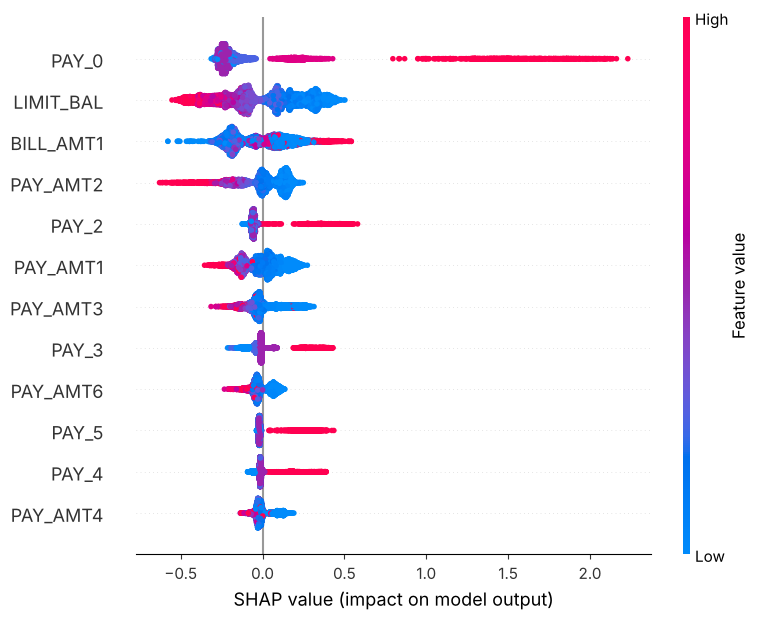

In [5]:
# Global view: all 6,000 test clients
shap_test = shap_raw(X_test)
shap.summary_plot(shap_test.values, X_test, max_display=12)

### Stress test: correlated features

We add an **exact copy of `PAY_0`** and retrain. No new information is added, so a "true" importance shouldn't change.

In [6]:
j = list(feature_names).index("PAY_0")
add_copy = lambda A: np.column_stack([A, A[:, j]])

model_dup = make_xgb()
model_dup.fit(add_copy(X_tr), y_tr, eval_set=[(add_copy(X_val), y_val)], verbose=False)
sv_dup = shap.TreeExplainer(model_dup, data=add_copy(background), feature_perturbation="interventional",
                            model_output="raw").shap_values(add_copy(preprocessor.transform(x_applicant)))[0]

pd.DataFrame({
    "test ROC-AUC": [roc_auc_score(y_test, y_proba), roc_auc_score(y_test, model_dup.predict_proba(add_copy(X_test_p))[:, 1])],
    "SHAP PAY_0": [shap_applicant["PAY_0"], sv_dup[j]],
    "SHAP PAY_0 copy": [np.nan, sv_dup[-1]],
}, index=["original", "with PAY_0 copy"]).round(3)

,test ROC-AUC,SHAP PAY_0,SHAP PAY_0 copy
original,0.78,1.645,NaN
with PAY_0 copy,0.78,1.261,0.437


Accuracy is unchanged, but `PAY_0`'s credit **drops by about a quarter** because the copy takes its share. When features carry the same information (late months, monthly bills), how credit is split among them is ambiguous.

## 2. LIME

Creates 5,000 fake clients around ours, scores them with XGBoost, and fits a simple linear model to those scores.

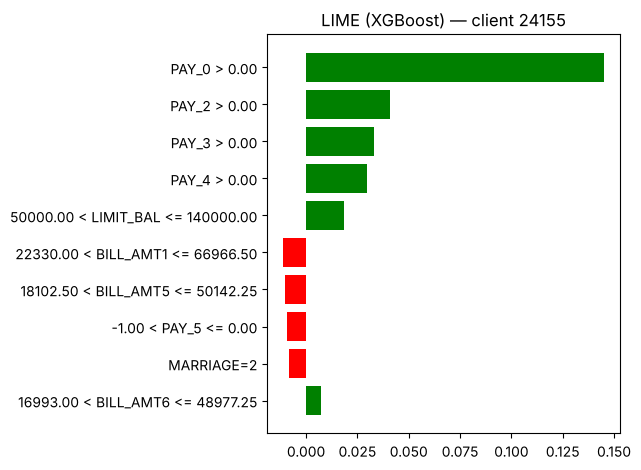

Fidelity: LIME's linear model predicts 0.36 vs XGBoost 0.70 (R² = 0.29)


In [7]:
cat_idx = [X_train.columns.get_loc(c) for c in categorical_features]

def run_lime(seed):
    return LimeTabularExplainer(X_train.values, feature_names=list(X_train.columns), class_names=["No default", "Default"],
                                categorical_features=cat_idx, mode="classification", random_state=seed
                                ).explain_instance(x0.values, xgb_predict_proba_raw, num_features=10, num_samples=5000)

lime_exp = run_lime(RANDOM_STATE)
lime_exp.as_pyplot_figure(); plt.title(f"LIME (XGBoost) — client {CLIENT_ID}"); plt.tight_layout(); plt.show()
print(f"Fidelity: LIME's linear model predicts {lime_exp.local_pred[0]:.2f} vs XGBoost {p_applicant:.2f} (R² = {lime_exp.score:.2f})")

### Stress test: stability (20 seeds, same client and model)

In [8]:
lime_runs = pd.DataFrame([{X_train.columns[i]: w for i, w in run_lime(s).as_map()[1]} for s in range(20)])

top_sets = [set(r.dropna().abs().nlargest(TOP_K).index) for _, r in lime_runs.iterrows()]
agreement = np.mean([len(a & b) for i, a in enumerate(top_sets) for b in top_sets[i + 1:]])
print(f"LIME re-run agreement: {agreement:.2f} of {TOP_K} reasons")

lime_freq = pd.DataFrame({
    f"in top {TOP_K} (%)": (lime_runs.abs().rank(axis=1, ascending=False) <= TOP_K).mean() * 100,
    "in top 10 (%)": lime_runs.notna().mean() * 100,
}).sort_values([f"in top {TOP_K} (%)", "in top 10 (%)"], ascending=False)
lime_freq.head(10)

LIME re-run agreement: 3.90 of 4 reasons


,in top 4 (%),in top 10 (%)
PAY_0,100.0,100.0
PAY_2,100.0,100.0
PAY_3,100.0,100.0
PAY_4,95.0,100.0
LIMIT_BAL,5.0,100.0
PAY_AMT3,0.0,85.0
BILL_AMT1,0.0,85.0
SEX,0.0,50.0
PAY_6,0.0,45.0
EDUCATION,0.0,40.0


The top 4 reasons barely move, but **lower down the list changes with the seed**. LIME's linear model also fits poorly (its prediction is far below XGBoost's 0.70), so its weights describe a rough approximation.

In [9]:
# SHAP vs LIME: compare ranks (different units)
ranks = pd.DataFrame({"SHAP rank": shap_applicant.abs().rank(ascending=False),
                      "LIME rank": lime_runs.mean().abs().rank(ascending=False)})
shap_top, lime_top = set(ranks["SHAP rank"].nsmallest(TOP_K).index), set(ranks["LIME rank"].nsmallest(TOP_K).index)
print(f"SHAP vs LIME top-{TOP_K} overlap: {len(shap_top & lime_top)}/{TOP_K}")
ranks.sort_values("SHAP rank").head(8)

SHAP vs LIME top-4 overlap: 4/4


,SHAP rank,LIME rank
PAY_0,1.0,1.0
PAY_3,2.0,3.0
PAY_2,3.0,2.0
PAY_4,4.0,4.0
PAY_AMT3,5.0,6.0
LIMIT_BAL,6.0,5.0
PAY_AMT1,7.0,21.0
BILL_AMT1,8.0,7.0


## 3. Counterfactuals (DiCE)

*What would need to change for XGBoost to approve this client?* DiCE needs categorical columns as strings; the wrapper converts them back before scoring.

In [10]:
class XGBForDiCE:
    def predict_proba(self, X_input):
        X_input = pd.DataFrame(X_input, columns=X_train.columns).copy()
        X_input[categorical_features] = X_input[categorical_features].astype(str).astype(float).astype(int)
        return xgb_predict_proba_raw(X_input)
    def predict(self, X_input):
        return (self.predict_proba(X_input)[:, 1] >= THRESHOLD).astype(int)

as_str = {c: str for c in categorical_features}
dice = dice_ml.Dice(
    dice_ml.Data(dataframe=X_train.astype(as_str).assign(DEFAULT=y_train), continuous_features=numeric_features, outcome_name="DEFAULT"),
    dice_ml.Model(model=XGBForDiCE(), backend="sklearn"), method="random")
x_dice = x_applicant.astype(as_str)

def show_cfs(cf):
    # Only the changed features of each counterfactual, plus XGBoost's P(default)
    ex = cf.cf_examples_list[0]
    rows = (ex.final_cfs_df_sparse if ex.final_cfs_df_sparse is not None else ex.final_cfs_df)[X_train.columns]
    changes = rows.astype(float).apply(lambda r: ", ".join(f"{c}: {x0[c]:g} -> {r[c]:g}" for c in X_train.columns if r[c] != x0[c]), axis=1)
    return pd.DataFrame({"changes": changes, "P(default)": XGBForDiCE().predict_proba(rows)[:, 1].round(3)})

In [11]:
# Unconstrained: DiCE may change anything
show_cfs(dice.generate_counterfactuals(x_dice, total_CFs=5, desired_class="opposite", random_seed=RANDOM_STATE))

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00,  4.03it/s]

100%|██████████| 1/1 [00:00<00:00,  4.02it/s]

,changes,P(default)
0,PAY_0: 2 -> 0,0.288
1,"AGE: 29 -> 58, BILL_AMT1: 55700 -> -145764",0.412
2,"PAY_0: 2 -> 0, PAY_4: 2 -> 0",0.261
3,"PAY_0: 2 -> 0, BILL_AMT1: 55700 -> 836583",0.417
4,"BILL_AMT1: 55700 -> -41540, PAY_AMT2: 2500 -> ...",0.314


All valid, but mostly unusable: becoming 29 years older, rewriting a past month, NT\$800,000+ bills or payments.

### Stress test: feasibility

The group's rule: only **September's status, bill and payment** may change. Lateness and the bill can only go down; the payment can only go up (capped at the 99th percentile).

In [12]:
permitted = {
    "PAY_0": [int(X_train["PAY_0"].min()), int(x0["PAY_0"])],
    "BILL_AMT1": [0, int(x0["BILL_AMT1"])],
    "PAY_AMT1": [int(x0["PAY_AMT1"]), int(X_train["PAY_AMT1"].quantile(0.99))],
}
show_cfs(dice.generate_counterfactuals(x_dice, total_CFs=5, desired_class="opposite",
                                       features_to_vary=list(permitted), permitted_range=permitted, random_seed=RANDOM_STATE))

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00,  4.38it/s]

100%|██████████| 1/1 [00:00<00:00,  4.35it/s]

,changes,P(default)
0,"PAY_0: 2 -> -2, BILL_AMT1: 55700 -> 14502",0.295
1,"PAY_0: 2 -> -1, PAY_AMT1: 5000 -> 35355",0.246
2,"PAY_0: 2 -> -2, PAY_AMT1: 5000 -> 29504",0.276
3,"PAY_0: 2 -> -1, PAY_AMT1: 5000 -> 22640",0.297
4,"PAY_0: 2 -> -1, PAY_AMT1: 5000 -> 66480",0.240


Realistic, but **every counterfactual requires September's status to improve**, which is already recorded by the time of the decision.

In [13]:
# What-ifs, including the two from the group's slide
what_ifs = {
    "Get current this month (PAY_0 -> -1)": {"PAY_0": -1},
    "Pay September's bill off (BILL_AMT1 -> 0)": {"BILL_AMT1": 0},
    "Be 8 months late in April (PAY_6 -> 8)": {"PAY_6": 8},
}
pd.DataFrame({k: {"XGBoost P(default)": round(xgb_predict_proba_raw(x_applicant.assign(**v))[0, 1], 3)}
              for k, v in what_ifs.items()}).T

,XGBoost P(default)
Get current this month (PAY_0 -> -1),0.296
Pay September's bill off (BILL_AMT1 -> 0),0.523
Be 8 months late in April (PAY_6 -> 8),0.736


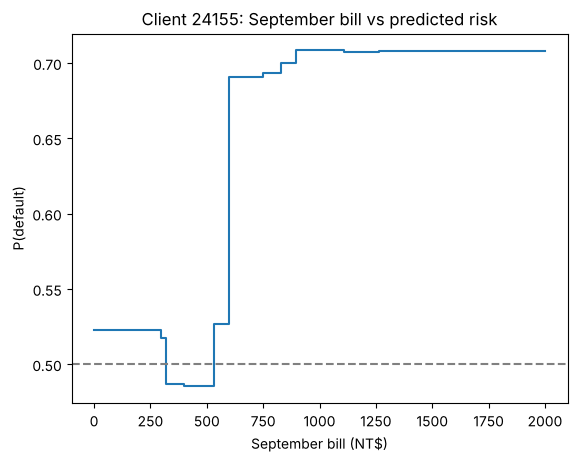

Approved only for bills between NT$320 and NT$525


In [14]:
# Paying the September bill off is still declined. Trace P(default) as only BILL_AMT1 changes.
grid = np.arange(0, 2001, 5)
probs = xgb_predict_proba_raw(pd.concat([x_applicant] * len(grid), ignore_index=True).assign(BILL_AMT1=grid))[:, 1]
plt.step(grid, probs, where="post"); plt.axhline(THRESHOLD, ls="--", color="grey")
plt.xlabel("September bill (NT$)"); plt.ylabel("P(default)"); plt.title(f"Client {CLIENT_ID}: September bill vs predicted risk"); plt.show()
print(f"Approved only for bills between NT${grid[probs < THRESHOLD].min()} and NT${grid[probs < THRESHOLD].max()}")

The model is a **staircase**: approved only in a narrow window of a few hundred NT\$, and declined again at NT\$0 (zero-bill clients default more often in the training data). A counterfactual can exploit a quirk of the model rather than give sound advice.

*Note:* the group slide gives XGBoost 0.43 for "8 months late in April", but this model gives about 0.74 (the what-if table). Check that slide value before presenting.

## 4. Comparing the three tools (client 24155)

Each tool answers a different question about the same XGBoost decline, so the table compares what each one is for, what it said about this client, and how it held up under its stress test.

In [ ]:
# Results pulled from the sections above
shap_top4 = ", ".join(shap_applicant.abs().nlargest(TOP_K).index)
lime_top4 = ", ".join(lime_runs.mean().abs().nlargest(TOP_K).index)
approved = grid[probs < THRESHOLD]

comparison = pd.DataFrame({
    "SHAP": {
        "Goal": "Attribute the prediction exactly to each feature",
        "Question answered": "How much did each feature push this client's risk up or down?",
        "Result for client 24155": f"Top {TOP_K}: {shap_top4}; PAY_0 adds {shap_applicant['PAY_0']:.2f} log-odds",
        "Stress test": "Add an exact copy of PAY_0 and retrain",
        "Stress test result": f"Same ROC-AUC, but PAY_0's credit falls {shap_applicant['PAY_0']:.2f} -> {sv_dup[j]:.2f}; the copy takes {sv_dup[-1]:.2f}",
        "Strength": "Exact for trees, additive, local and global views",
        "Limitation": "Credit among correlated features is arbitrary",
    },
    "LIME": {
        "Goal": "Approximate the model locally with a linear model",
        "Question answered": "Which features matter in a simple model fit around this client?",
        "Result for client 24155": f"Top {TOP_K}: {lime_top4}; overlap with SHAP {len(shap_top & lime_top)}/{TOP_K}",
        "Stress test": "Re-run with 20 random seeds",
        "Stress test result": f"Top {TOP_K} agreement {agreement:.2f}/{TOP_K}, lower ranks change; fit predicts {lime_exp.local_pred[0]:.2f} vs {p_applicant:.2f} (R² = {lime_exp.score:.2f})",
        "Strength": "Model-agnostic, easy to read",
        "Limitation": "Depends on sampling; low fidelity to XGBoost",
    },
    "Counterfactuals (DiCE)": {
        "Goal": "Find changes that flip the decision",
        "Question answered": "What would the client need to change to be approved?",
        "Result for client 24155": "Unconstrained: valid but unrealistic (age +29 years, extreme bills)",
        "Stress test": "Only September's status, bill and payment may change, in a feasible direction",
        "Stress test result": f"All need PAY_0 to improve (already recorded); paying the bill off still declined, approved only for bills NT${approved.min()}–{approved.max()}",
        "Strength": "Actionable, speaks the client's language",
        "Limitation": "Valid ≠ feasible; can exploit quirks of the model",
    },
})
with pd.option_context("display.max_colwidth", None):
    display(comparison.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

SHAP and LIME agree on **why** the client was declined (the late months, led by `PAY_0`). Counterfactuals answer a different question, **what would change the decision**, and point to the same feature. The tools work best together: SHAP for an exact attribution, LIME as a model-agnostic cross-check, and counterfactuals for recourse, as long as feasibility is enforced.

## Takeaways

1. All three methods point to **September's late payment (`PAY_0`)** as the main reason for the decline.
2. **SHAP**: exact and stable, but credit among correlated features is ambiguous.
3. **LIME**: stable top reasons, but low fidelity and unstable details.
4. **Counterfactuals**: valid ≠ actionable; even constrained ones rely on past behaviour or quirks of the model.
5. Explanations describe **one model**, not causes of default. They're **diagnostic tools, not certificates of trust**.